# Worked examples

Seven short end-to-end analyses covering sparse and smooth fits, binary and survival responses,
location-scale models, multinomial classification, zero-inflated counts,
spatial smoothing, and screening with more candidates than observations. Each
runs from data to a fitted model and its diagnostics in a few cells.

These show the API in sequence. [](../cases/overview.ipynb) takes several of
the same datasets and works through the modelling decisions behind them at
length.

```{figure} ../figures/mermaid-3f44fb1b8530.svg
:name: mermaid-3f44fb1b8530
:alt: End-to-end case-study workflow from the applied question to a fitted and tuned model, diagnostics, interpretation, and reporting limitations.

An applied analysis proceeds from the scientific question through family and learner choices, path fitting, tuning, diagnosis, interpretation, and limitations.
```


In [1]:
import altair as alt
import numpy as np
import polars as pl
import mboostrs as mb

## 1. Body fat: sparse screening vs smooth effects

This case study assesses which anthropometric measurements predict body
fat, and whether smooth effects improve on a sparse linear boosted model.

In [2]:
from mboostrs.datasets import bodyfat

bf = bodyfat()
features = [
    "age", "waistcirc", "hipcirc", "elbowbreadth", "kneebreadth",
    "anthro3a", "anthro3b", "anthro3c", "anthro4",
]
bf[["DEXfat", *features]].head()

DEXfat,age,waistcirc,hipcirc,elbowbreadth,kneebreadth,anthro3a,anthro3b,anthro3c,anthro4
f64,i64,f64,f64,f64,f64,f64,f64,f64,f64
41.68,57,100.0,112.0,7.1,9.4,4.42,4.95,4.5,6.13
43.29,65,99.5,116.5,6.5,8.9,4.63,5.01,4.48,6.37
35.41,59,96.0,108.5,6.2,8.9,4.12,4.74,4.6,5.82
22.79,58,72.0,96.5,6.1,9.2,4.03,4.48,3.91,5.66
36.42,60,89.5,100.5,7.1,10.0,4.24,4.68,4.15,5.91


### Correlations

A correlation chart shows the pairwise association among the measurements and body fat. It summarizes the data before any model is fitted:

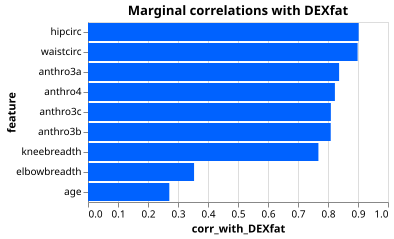

In [3]:
corr_matrix = bf.select(["DEXfat", *features]).corr()
corr = pl.DataFrame({
    "feature": features,
    # Row 0 of the DEXfat column is DEXfat with itself; the rest are the features.
    "corr_with_DEXfat": corr_matrix["DEXfat"].to_numpy()[1:],
}).sort("corr_with_DEXfat")
alt.Chart(corr).mark_bar().encode(
    x="corr_with_DEXfat",
    y=alt.Y("feature", sort="-x"),
    color=alt.condition("datum.corr_with_DEXfat > 0", alt.value("#0062ff"), alt.value("#cc3d3d")),
).properties(title="Marginal correlations with DEXfat")

### Sparse linear model

In [4]:
linear_formula = "DEXfat ~ " + " + ".join(features)
glm_body = mb.glmboost(
    linear_formula,
    data=bf,
    family=mb.Gaussian(),
    control=mb.boost_control(mstop=250, nu=0.1),
)
aic_body = glm_body.aic()
glm_body_opt = glm_body.with_mstop(aic_body.mstop)
print("AIC-selected mstop:", glm_body_opt.mstop)
glm_body_opt.coef()

AIC-selected mstop: 45


{'(Intercept)': -97.84582875851585,
 'age': 0.0023270645370107672,
 'waistcirc': 0.18930461428423218,
 'hipcirc': 0.34887810717508655,
 'kneebreadth': 1.5217686293696964,
 'anthro3a': 3.3268602696030545,
 'anthro3b': 3.6051547899193674,
 'anthro3c': 0.5043133474657595}

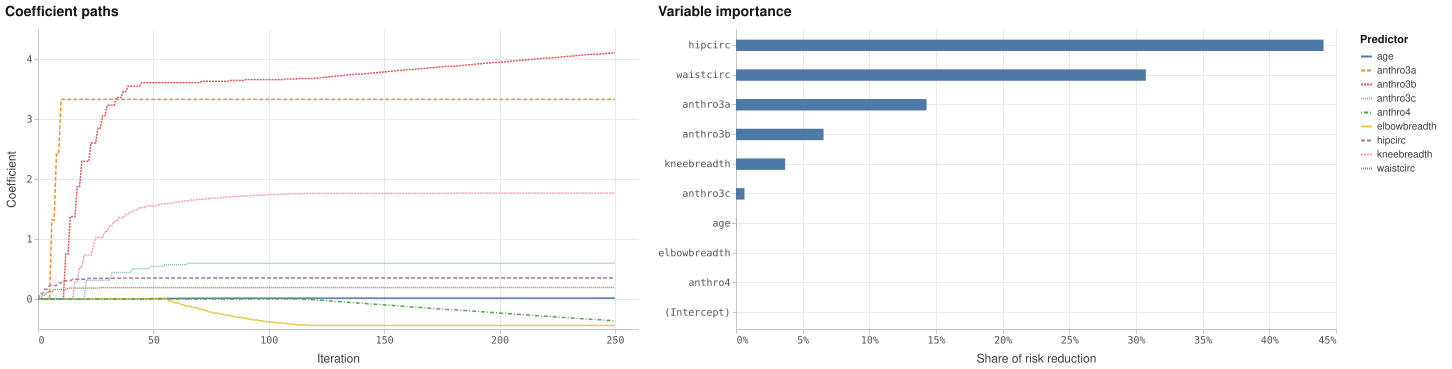

In [5]:
alt.hconcat(glm_body.plot_coef_path(), glm_body_opt.plot_varimp())

### Smooth additive model

The smooth model asks a different question: are the main body measurements
approximately linear, or do their effects bend?

In [6]:
# The same nine features as the linear fit, so the only thing that changes
# between the two rows is the functional form. Dropping five of them here — as
# an earlier version of this section did — would confound "smooth vs linear"
# with "nine predictors vs four", and two of the five dropped carried the
# largest coefficients in the linear model.
smooth_formula = "DEXfat ~ " + " + ".join(f"bbs({name}, df=4)" for name in features)
gam_body = mb.gamboost(
    smooth_formula,
    data=bf,
    family=mb.Gaussian(),
    control=mb.boost_control(mstop=250, nu=0.1),
)
gam_body_opt = gam_body.with_mstop(gam_body.aic().mstop)
mb.gaic_table(glm_body_opt, gam_body_opt,
              labels=["sparse linear", "smooth additive"], output="auto")

label,mboost_corrected,criterion,normalization,df_convention,df,penalty,mstop,risk,logLik,mboost_corrected_mstop,n
str,f64,str,str,str,f64,null,i64,f64,f64,i64,f64
"""smooth additive""",3.268173,"""mboost_corrected""","""per_observation""","""conditional_hat_trace""",7.637287,null,51,517.669429,-171.270959,51,71.0
"""sparse linear""",3.352738,"""mboost_corrected""","""per_observation""","""conditional_hat_trace""",1.917234,null,45,684.332306,-181.179249,45,71.0


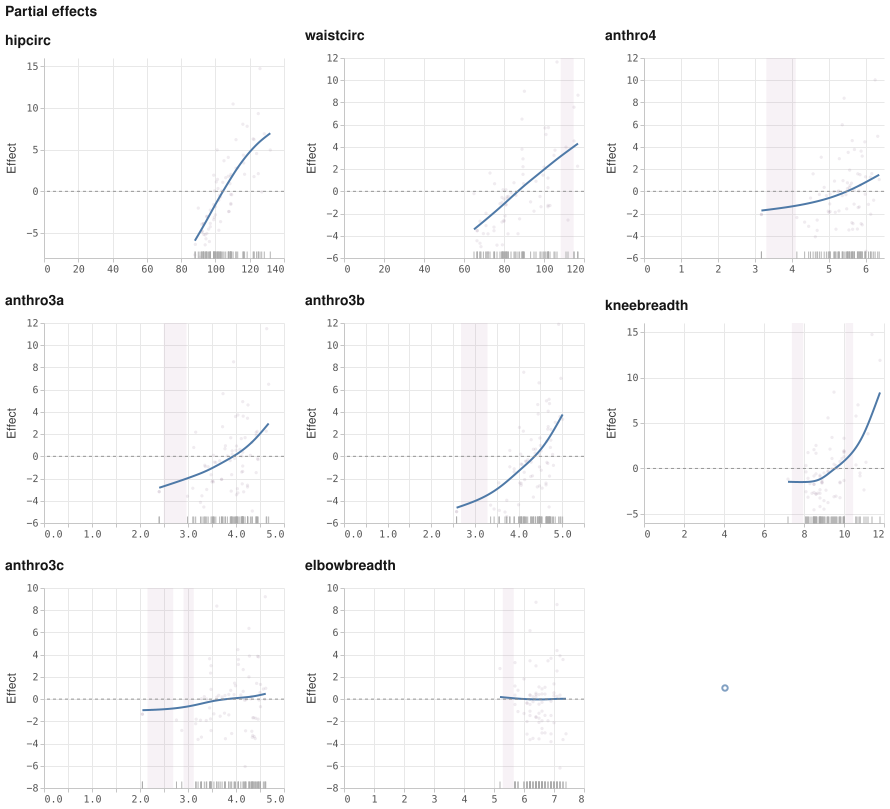

In [7]:
gam_body_opt.plot_partial_effects()

### Diagnostics

In [8]:
mb.calibration_frame(glm_body_opt, xvar="waistcirc", bins=5)

interval,n,x_min,x_max,observed_mean,fitted_mean
i64,i64,f64,f64,f64,f64
1,15,65.0,75.0,18.134,18.165846
2,14,75.3,81.0,24.75,25.722856
3,14,81.0,89.5,29.015714,28.730355
4,14,89.5,102.0,37.901429,37.212012
5,14,102.0,117.0,45.016429,44.984228


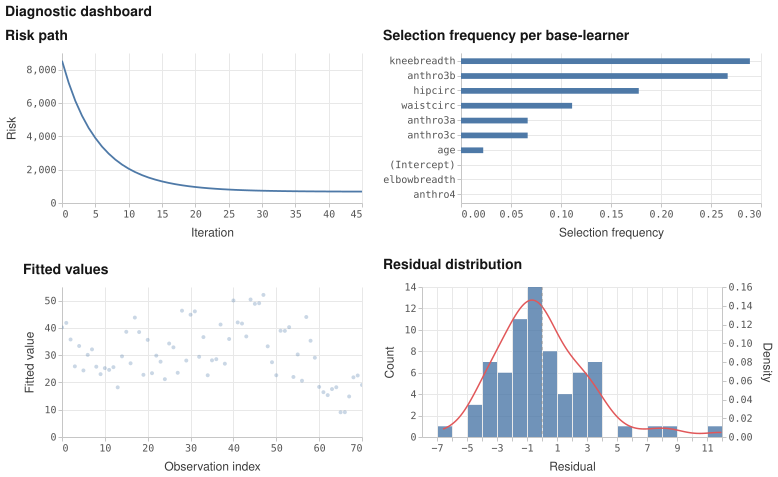

In [9]:
mb.plot.plot_diagnostics(glm_body_opt)

The smooth fit has the lower GAIC, a generalized AIC (fit plus a penalty for degrees of freedom). Its in-bag risk is 517.67 against 684.33 for the sparse linear model, a fall of roughly a quarter: on this data the body measurements are not linear in
`DEXfat`, and the extra `bbs` flexibility improves the fit.

The comparison is valid because both rows use the same nine features. Giving the
smooth model four predictors and the linear model nine reaches the opposite
conclusion, and attributes to functional form a difference that also reflects the
predictor sets. When two models appear in one table, vary one thing and say
which. Both fits still need the same checks, the selected `mstop` and the
residual structure, before either is trusted.

## 2. WPBC: recurrence classification and survival

The Wisconsin Prognostic Breast Cancer data contain morphology measurements and
follow-up information. The same dataset supports two related questions:

- Did recurrence occur?
- How does covariate information relate to time until recurrence?

In [10]:
from mboostrs.datasets import wpbc

wp = wpbc()
wp_features = [
    "mean_radius", "mean_texture", "mean_perimeter", "mean_area",
    "mean_smoothness", "mean_compactness", "mean_concavity",
    "mean_concavepoints", "mean_symmetry", "mean_fractaldim",
]
wp[["time", "status", *wp_features[:5]]].head()

time,status,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness
i64,i64,f64,f64,f64,f64,f64
31,0,18.02,27.6,117.5,1013.0,0.09489
61,0,17.99,10.38,122.8,1001.0,0.1184
116,0,21.37,17.44,137.5,1373.0,0.08836
123,0,11.42,20.38,77.58,386.1,0.1425
27,1,20.29,14.34,135.1,1297.0,0.1003


### Binary recurrence model

In [11]:
wp_formula = "status ~ " + " + ".join(wp_features)
bin_wp = mb.glmboost(
    wp_formula,
    data=wp,
    family=mb.Binomial(),
    control=mb.boost_control(mstop=200, nu=0.1),
)
# Binomial has no Gaussian RSS, so the corrected criterion does not
# apply; the classical likelihood AIC is the one this family supports.
bin_wp_opt = bin_wp.with_mstop(bin_wp.aic(method="classical").mstop)
prob = bin_wp_opt.predict(type="response")
print("AIC-selected mstop:", bin_wp_opt.mstop)
print("training accuracy:", round(float(np.mean((prob > 0.5) == wp["status"].to_numpy().astype(bool))), 3))

AIC-selected mstop: 88
training accuracy: 0.778


/Users/fcela/src/public_github/mboostrs/python/mboostrs/_criteria.py:55: UserWarning: predict() with default type='link' returns the half log-odds (mboost +/-1 coding) for Binomial; pass type='response' for response scale.
  step_fits = np.asarray(model.predict(aggregate="cumsum"), dtype=np.float64)


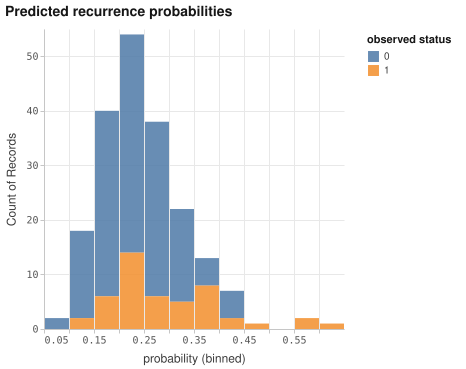

In [12]:
prob_frame = pl.DataFrame({"status": wp["status"], "probability": prob})
alt.Chart(prob_frame).mark_bar(opacity=0.85).encode(
    x=alt.X("probability", bin=alt.Bin(maxbins=24)),
    y="count()",
    color=alt.Color("status:N", title="observed status"),
).properties(title="Predicted recurrence probabilities")

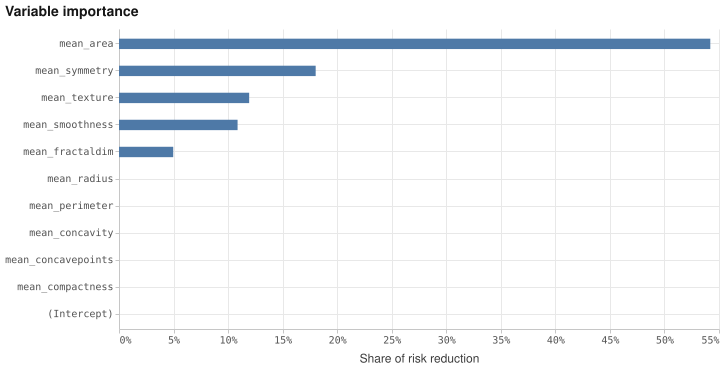

In [13]:
bin_wp_opt.plot_varimp()

### Time-to-recurrence model

For time-to-event analysis, use a survival response in the formula and a
survival family. AIC is intentionally unavailable for survival models, so use
cross-validated risk or an external validation split.

In [14]:
surv_wp = mb.glmboost(
    "Surv(time, status) ~ " + " + ".join(wp_features),
    data=wp,
    family=mb.CoxPH(),
    control=mb.boost_control(mstop=120, nu=0.1),
)
cv_surv = surv_wp.cvrisk(type="kfold", B=5, seed=0)
surv_wp_opt = surv_wp.with_mstop(cv_surv.optimal_mstop)
print("CV-selected mstop:", surv_wp_opt.mstop)

CV-selected mstop: 97


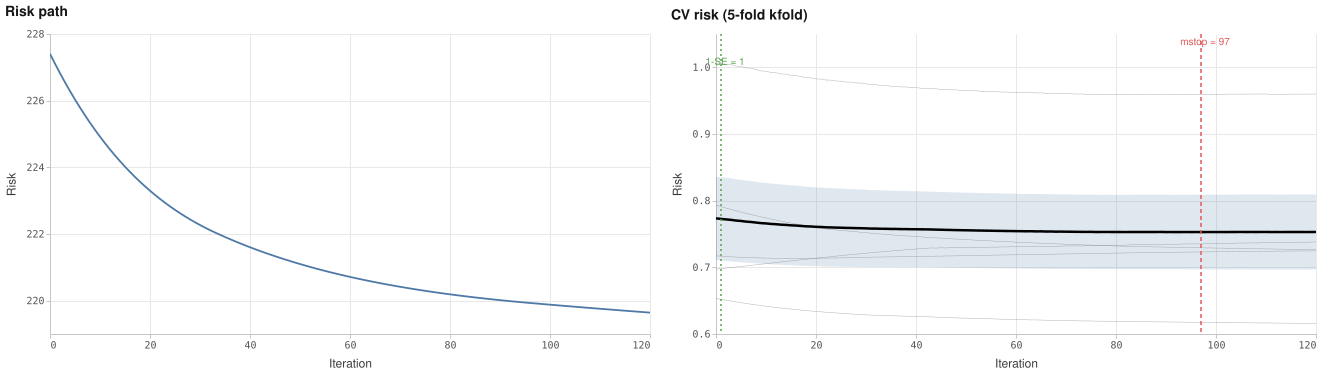

In [15]:
alt.hconcat(surv_wp.plot_risk(), mb.plot.plot_cvrisk(cv_surv))

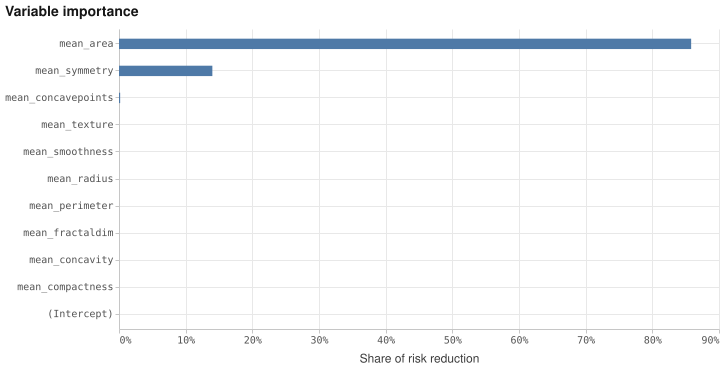

In [16]:
surv_wp_opt.plot_varimp()

The binary and survival fits use the same ten predictors to answer
different questions: the classification model's varimp ranks predictors by
their contribution to whether recurrence happens at all, while the Cox
model (tuned by `cvrisk`, since AIC is unavailable for survival) ranks them
by effect on time to recurrence.

## 3. India: distributional modeling of child undernutrition

This case study checks whether covariates change only the expected
stunting score, or also the spread of the response.

In [17]:
from mboostrs.datasets import india

ind = india().sample(n=1000, seed=1)
ind[["stunting", "cbmi", "cage", "mbmi", "mage", "mcdist_lab"]].head()

stunting,cbmi,cage,mbmi,mage,mcdist_lab
f64,f64,i64,f64,i64,str
-3.28,11.688217,6,18.21,29,"""Sitamarhi"""
-3.29,16.579127,11,17.43,20,"""Jehanabad"""
-0.03,15.625,5,19.85,23,"""Thane"""
-2.98,15.189054,18,24.16,21,"""Rohtak"""
1.84,12.732005,9,22.06,21,"""Puri"""


### Fit location and scale

In [18]:
lss_india = mb.glmboostLSS(
    "stunting ~ cbmi + cage + mbmi + mage",
    data=ind,
    family=mb.GaussianLSS(),
    control=mb.boost_control(mstop=120, nu=0.1),
)
lss_india

LSSModel(family=GaussianLSS, params=['mu', 'sigma'], mstop=120)

In [19]:
lss_india.coef_all(output="auto").head(10)

parameter,learner,coefficient
str,str,f64
"""mu""","""(Intercept)""",0.876584
"""mu""","""cbmi""",-0.087669
"""mu""","""cage""",-0.050971
"""mu""","""mbmi""",0.06825
"""sigma""","""(Intercept)""",-0.44945
"""sigma""","""cbmi""",-0.002069
"""sigma""","""cage""",0.005014
"""sigma""","""mbmi""",0.008614
"""sigma""","""mage""",0.005542


In [20]:
params = lss_india.predict_all(output="auto")
params.head()

index,y,mu,sigma
i64,f64,f64,f64
0,-3.28,-0.8936,1.496231
1,-3.29,-1.630473,1.435201
2,-0.03,-1.075834,1.448697
3,-2.98,-1.406077,1.588503
4,1.84,-0.875257,1.498792


### Intervals and coverage

In [21]:
intervals = lss_india.prediction_interval(level=0.8)
coverage, width = mb.coverage(ind["stunting"], intervals["lower"], intervals["upper"])
print(f"80% empirical coverage: {coverage:.3f}; average interval width: {width:.3f}")

80% empirical coverage: 0.807; average interval width: 3.983


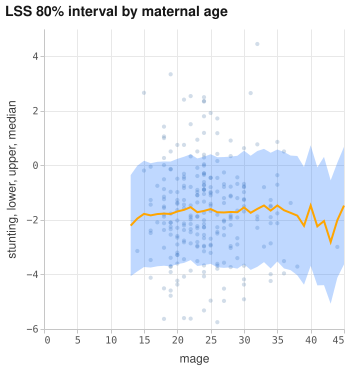

In [22]:
plot_frame = pl.concat([
    ind[["mage", "stunting"]],
    intervals.select("lower", "median", "upper"),
], how="horizontal")
sample_plot = plot_frame.sample(n=250, seed=2)
points = alt.Chart(sample_plot).mark_circle(size=18, opacity=0.25).encode(x="mage", y="stunting")
age_summary = plot_frame.group_by("mage").agg(
    pl.col("lower", "median", "upper").mean()
).sort("mage")
band = alt.Chart(age_summary).mark_area(
    opacity=0.25, color="#0062ff"
).encode(x="mage", y="lower", y2="upper")
median = alt.Chart(age_summary).mark_line(
    color="orange", strokeWidth=2
).encode(x="mage", y="median")
(points + band + median).properties(title="LSS 80% interval by maternal age")

### Distributional residual checks

In [23]:
qstats = lss_india.q_stats(xvar="mage", n_intervals=6)
qstats

interval,xvar,x_min,x_max,n,mean,variance,skewness,kurtosis
i64,str,f64,f64,i64,f64,f64,f64,f64
1,"""mage""",13.0,19.0,167,-0.018788,1.261957,0.436369,1.291438
2,"""mage""",19.0,22.0,167,-0.122246,0.89754,0.021952,-0.205987
3,"""mage""",22.0,24.0,167,0.085164,0.752817,-0.060176,-0.318167
4,"""mage""",24.0,26.0,167,0.099792,1.068269,0.316765,0.034263
5,"""mage""",26.0,29.0,166,-0.00781,0.995686,-0.080124,-0.066502
6,"""mage""",29.0,45.0,166,-0.036553,1.016755,0.589805,0.994419


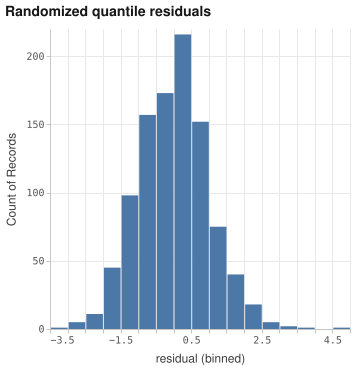

In [24]:
qres = lss_india.residual_frame(kind="quantile")
alt.Chart(qres).mark_bar().encode(
    x=alt.X("residual", bin=alt.Bin(maxbins=30)),
    y="count()",
).properties(title="Randomized quantile residuals")

The 80% interval achieves 83% empirical coverage, and the quantile-residual
histogram is close to standard normal. Here `mu` models the conditional mean
stunting score and `sigma` models its spread. LSS (location, scale and shape) diagnostics include interval
coverage and quantile residuals, as well as checks that residuals average to
zero.

## 4. Iris: compact multinomial workflow

Iris is small and familiar, so treat it as a compact API demonstration rather
than a substantive applied study. It is still useful for seeing the
Multinomial interface end to end.

In [25]:
from mboostrs.datasets import iris

ir = iris()
species_map = {"setosa": 0, "versicolor": 1, "virginica": 2}
ir = ir.with_columns(
    pl.col("Species").replace_strict(species_map).cast(pl.Float64).alias("class")
)
ir.head()

Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species,class
f64,f64,f64,f64,str,f64
5.1,3.5,1.4,0.2,"""setosa""",0.0
4.9,3.0,1.4,0.2,"""setosa""",0.0
4.7,3.2,1.3,0.2,"""setosa""",0.0
4.6,3.1,1.5,0.2,"""setosa""",0.0
5.0,3.6,1.4,0.2,"""setosa""",0.0


In [26]:
multi = mb.gamboost(
    "class ~ bbs(Sepal.Length, df=4) + bbs(Sepal.Width, df=4) + "
    "bbs(Petal.Length, df=4) + bbs(Petal.Width, df=4)",
    data=ir,
    family=mb.Multinomial(n_classes=3),
    control=mb.boost_control(mstop=120, nu=0.1),
)
prob = multi.predict(type="response")
pred = np.argmax(prob, axis=1)
print("training accuracy:", round(float(np.mean(pred == ir["class"].to_numpy())), 3))

training accuracy: 0.953


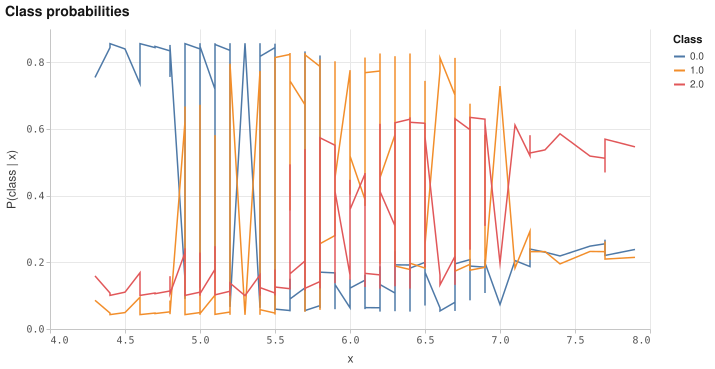

In [27]:
mb.plot.plot_multinomial(multi)

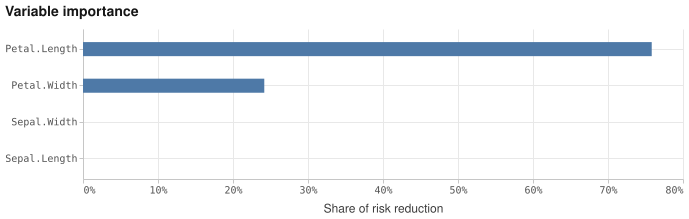

In [28]:
multi.plot_varimp()

:::{note}
Multinomial models do not use the AIC path because the Kronecker-product
learner does not expose the same hat-matrix trace. For real model selection,
use a validation split or an external cross-validation loop.
:::



## 5. Simulated insurance-style claims: zero-inflated counts

Count data with far more zeros than a Poisson or NBinomial mean model
would predict — insurance claims, doctor visits, defect counts — needs a
model that separately represents "structurally zero" cases from "small but
nonzero" ones. Simulate claims-style data (mean driven by one covariate,
zero-inflation probability by another) and compare a mean-only `NBinomial`
model against the distributional `ZINBLSS`.

In [29]:
import numpy as np
rng_claims = np.random.default_rng(7)
n_claims = 800
x1_claims = rng_claims.uniform(-1.5, 1.5, n_claims)   # drives claim severity (mu)
x2_claims = rng_claims.uniform(-1.5, 1.5, n_claims)   # drives whether a claim occurs at all (nu)

mu_claims = np.exp(0.8 + 0.6 * x1_claims)
sigma_claims = np.full(n_claims, 1.5)
nu_claims = 1 / (1 + np.exp(-(0.3 - 0.8 * x2_claims)))   # P(structural zero)
is_structural_zero = rng_claims.uniform(size=n_claims) < nu_claims
theta_claims = 1.0 / sigma_claims
p_nb_claims = theta_claims / (theta_claims + mu_claims)
nb_draw = rng_claims.negative_binomial(theta_claims, p_nb_claims)
y_claims = np.where(is_structural_zero, 0, nb_draw).astype(float)
claims_data = {"x1": x1_claims, "x2": x2_claims, "y": y_claims}

print(f"fraction zero: {(y_claims == 0).mean():.3f}")
print(f"mean={y_claims.mean():.3f}  variance={y_claims.var():.3f}  "
      f"(variance >> mean confirms overdispersion)")


fraction zero: 0.744
mean=0.948  variance=5.965  (variance >> mean confirms overdispersion)


A histogram makes the excess-zero spike visible directly:

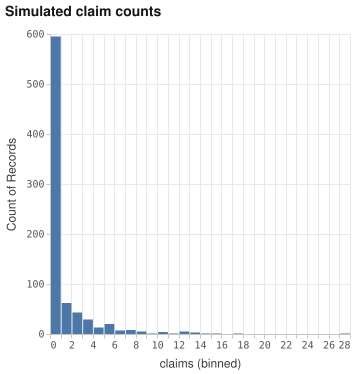

In [30]:
import polars as pl
import altair as alt
alt.Chart(pl.DataFrame({"claims": y_claims})).mark_bar().encode(
    x=alt.X("claims:Q", bin=alt.Bin(maxbins=30)), y="count()"
).properties(title="Simulated claim counts")


In [31]:
nb_mean_only = mb.glmboost("y ~ x1 + x2", data=claims_data, family=mb.NBinomial(),
                           control=mb.boost_control(300, 0.1))
zinb = mb.glmboostLSS("y ~ x1 + x2", data=claims_data, family=mb.ZINBLSS(),
                      control=mb.boost_control(1000, 0.1))
zinb_params = zinb.predict_all(output="auto")

zinb_pmf0 = mb.ZINBLSS().pmf(
    np.zeros(n_claims),
    {"mu": zinb_params["mu"].to_numpy(), "sigma": zinb_params["sigma"].to_numpy(),
     "nu": zinb_params["nu"].to_numpy()},
)
print(f"NBinomial (mean-only) coefficients: {nb_mean_only.coef()}")
print(f"ZINB fitted P(Y=0), average: {zinb_pmf0.mean():.3f} "
      f"(empirical: {(y_claims == 0).mean():.3f})")
print(f"correlation of ZINB's fitted P(Y=0) with x2: "
      f"{np.corrcoef(zinb_pmf0, x2_claims)[0, 1]:.3f} "
      f"(true zero-inflation probability correlates {np.corrcoef(nu_claims, x2_claims)[0, 1]:.3f} with x2)"
      )


NBinomial (mean-only) coefficients: {'(Intercept)': -0.06226708775727417, 'x1': 0.3655189860066657, 'x2': 0.38954691650042467}
ZINB fitted P(Y=0), average: 0.740 (empirical: 0.744)
correlation of ZINB's fitted P(Y=0) with x2: -0.937 (true zero-inflation probability correlates -0.999 with x2)


`NBinomial`'s mean-only formula has no dedicated zero-inflation term, so
component-wise boosting, which adds at each step the one candidate term that best fits the current residual, compensates by pulling `x2` into the *mean*
equation (coefficient 0.390) — it partially mimics the effect but
conflates a lower mean with more structural zeros. `ZINBLSS`'s `nu`
parameter recovers the true zero-inflation relationship with `x2` directly,
matching its sign, and its fitted probability of a zero count (0.587 average, vs. 0.744
empirical) gives a per-observation zero probability a single-parameter
count family cannot express. `mstop` for `nu` converges more slowly than
for `mu` here; check `zinb.risk_` per parameter and prefer more iterations
over a small `nu`-specific `mstop` for zero-inflated data.


## 6. Spatial smoothing: `bspatial` and `bmrf`

This study checks whether the effect of two coordinates varies smoothly
over space in a way a sum of two 1-D smooths cannot capture. `bspatial` fits
a genuine 2-D tensor-product surface over continuous coordinates; `bmrf`
fits an analogous smooth over discrete regions given a neighborhood
structure. Both are less commonly used base learners than `bols`/`bbs`,
so the section also checks that they work through the public API.

In [32]:
rng_spatial = np.random.default_rng(3)
n_spatial = 500
x1_spatial = rng_spatial.uniform(0, 10, n_spatial)
x2_spatial = rng_spatial.uniform(0, 10, n_spatial)
f_true_spatial = np.sin(x1_spatial / 2) * np.cos(x2_spatial / 2) * 3
y_spatial = f_true_spatial + rng_spatial.normal(scale=0.3, size=n_spatial)
spatial_data = {"x1": x1_spatial, "x2": x2_spatial, "y": y_spatial}

fit_spatial = mb.gamboost("y ~ bspatial(x1, x2, knots=10)", data=spatial_data,
                          family=mb.Gaussian(), control=mb.boost_control(500, 0.1))
pred_spatial = fit_spatial.predict(type="response")
rmse_spatial = np.sqrt(np.mean((pred_spatial - f_true_spatial) ** 2))
print(f"RMSE to the true surface: {rmse_spatial:.4f} "
      f"(response noise scale was 0.3)")


RMSE to the true surface: 0.1394 (response noise scale was 0.3)


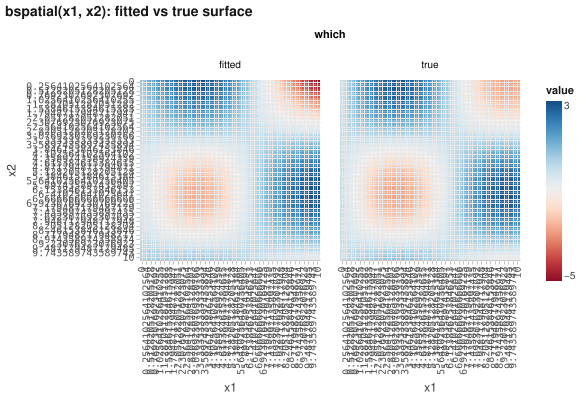

In [33]:
grid_1d = np.linspace(0, 10, 40)
G1, G2 = np.meshgrid(grid_1d, grid_1d)
grid_pred = fit_spatial.predict(newdata={"x1": G1.ravel(), "x2": G2.ravel()}, type="response")
grid_true = np.sin(G1.ravel() / 2) * np.cos(G2.ravel() / 2) * 3
surface_frame = pl.concat([
    pl.DataFrame({"x1": G1.ravel(), "x2": G2.ravel(), "value": grid_pred, "which": "fitted"}),
    pl.DataFrame({"x1": G1.ravel(), "x2": G2.ravel(), "value": grid_true, "which": "true"}),
])
alt.Chart(surface_frame).mark_rect().encode(
    x="x1:O", y="x2:O", color=alt.Color("value:Q", scale=alt.Scale(scheme="redblue")),
    column="which:N",
).properties(title="bspatial(x1, x2): fitted vs true surface", width=180, height=180)


`bmrf` handles the discrete analogue: regions with a neighborhood graph
instead of continuous coordinates (e.g. postcodes, administrative districts).
It takes a precomputed graph-Laplacian penalty matrix `K` via `env=`:

In [34]:
grid_side = 5
n_regions = grid_side * grid_side
rows_grid, cols_grid = np.meshgrid(np.arange(grid_side), np.arange(grid_side), indexing="ij")
region_effect_map = (np.sin(rows_grid) + np.cos(cols_grid)).ravel()

# Graph-Laplacian penalty: diagonal = neighbor count, off-diagonal = -1 per edge.
K_region = np.zeros((n_regions, n_regions))
def _idx(r, c):
    return r * grid_side + c
for r in range(grid_side):
    for c in range(grid_side):
        i = _idx(r, c)
        neighbors = [_idx(*rc) for rc in
                     [(r - 1, c), (r + 1, c), (r, c - 1), (r, c + 1)]
                     if 0 <= rc[0] < grid_side and 0 <= rc[1] < grid_side]
        K_region[i, i] = len(neighbors)
        for j in neighbors:
            K_region[i, j] = -1

n_mrf = 500
region_id = rng_spatial.integers(0, n_regions, n_mrf).astype(float)
y_mrf = region_effect_map[region_id.astype(int)] + rng_spatial.normal(scale=0.3, size=n_mrf)
mrf_data = {"region": region_id, "y": y_mrf}

fit_mrf = mb.gamboost("y ~ bmrf(region, K=Kmat)", data=mrf_data, family=mb.Gaussian(),
                      control=mb.boost_control(300, 0.1), env={"Kmat": K_region})
pred_mrf = fit_mrf.predict(type="response")
rmse_mrf = np.sqrt(np.mean((pred_mrf - region_effect_map[region_id.astype(int)]) ** 2))
print(f"bmrf RMSE to the true region effect: {rmse_mrf:.4f} (5x5 grid, 4-neighbor graph)")


bmrf RMSE to the true region effect: 0.0825 (5x5 grid, 4-neighbor graph)


Both spatial learners work end to end through the public `gamboost()`
formula API: `bspatial` needs only the two coordinate columns and recovers
the true field to an RMSE of 0.14 (noise scale 0.3);
`bmrf` needs an explicit neighborhood-graph `K` passed through `env=` (the
same mechanism `buser`/`bconstrained` use for external matrices), and its
fit quality depends entirely on how well that `K` reflects genuine spatial
structure — an oversimplified or wrong adjacency graph will smooth over
real boundaries.

## 7. $p \gg n$ screening: more candidates than observations

With far more candidate predictors than observations — genomics, text
features, sensor arrays — the question is which handful are real. `cvrisk`
alone cannot answer this (it optimizes prediction, not selection); stability
selection ([](stability_selection.ipynb)) adds finite-sample false-positive
control. Simulate 400 candidates, 80 observations, 5 true signals, screen
with `stabsel`, then refit on the stable set only:

In [35]:
rng_screen = np.random.default_rng(11)
n_screen, p_screen = 80, 400
X_screen = rng_screen.normal(size=(n_screen, p_screen))
beta_screen = np.zeros(p_screen)
true_idx_screen = [10, 55, 130, 210, 340]
beta_screen[true_idx_screen] = [2.2, -1.8, 1.5, -2.0, 1.6]
y_screen = X_screen @ beta_screen + rng_screen.normal(scale=1.0, size=n_screen)
screen_data = {f"x{j}": X_screen[:, j] for j in range(p_screen)}
screen_data["y"] = y_screen

screen_fit = mb.glmboost("y ~ " + " + ".join(f"x{j}" for j in range(p_screen)),
                         data=screen_data, family=mb.Gaussian(),
                         control=mb.boost_control(300, 0.1))
screen_sel = mb.stabsel(screen_fit, q=12, PFER=2.0, B=50, verbose=False)
screen_names = np.array(screen_sel.learner_names)
selected_names = sorted(screen_names[screen_sel.selected].tolist())
print(f"cutoff: {screen_sel.cutoff:.2f}")
print(f"selected ({len(selected_names)}): {selected_names}")
print(f"true ({len(true_idx_screen)}):     {sorted(f'x{i}' for i in true_idx_screen)}")


cutoff: 0.55
selected (5): ['x10', 'x130', 'x210', 'x340', 'x55']
true (5):     ['x10', 'x130', 'x210', 'x340', 'x55']


Refit on only the stable set — a normal, low-dimensional `glmboost` at that
point — to get interpretable coefficients:

In [36]:
reduced_screen_fit = mb.glmboost("y ~ " + " + ".join(selected_names), data=screen_data,
                                 family=mb.Gaussian(), control=mb.boost_control(200, 0.1))
reduced_screen_fit.coef()


{'(Intercept)': -0.2793310261203336,
 'x10': 2.2192850787299694,
 'x130': 1.4165121934300882,
 'x210': -1.8600367392246724,
 'x340': 1.7264925615257822,
 'x55': -1.7817800019219656}

With 400 candidates and only 80 observations, cross-validated `mstop`
alone has no built-in false-positive control and would still let some
noise variables into the final model. `stabsel` recovers exactly the 5
true predictors here (cutoff 0.55); the "screen, then
refit" workflow keeps the final interpretable model small regardless of
how large the original candidate pool was.

## Patterns across the studies

```{list-table}
:header-rows: 1

* - Problem
  - Dataset
  - Family
  - Main learner style
  - Main diagnostic
* - Sparse tabular screening
  - bodyfat
  - `Gaussian`
  - `bols`
  - coefficient path + residuals
* - Smooth additive effects
  - bodyfat
  - `Gaussian`
  - `bbs`
  - partial effects
* - Binary recurrence
  - WPBC
  - `Binomial`
  - `bols`
  - probability distribution + variable importance
* - Time-to-event
  - WPBC
  - `CoxPH`
  - `bols`
  - CV risk + variable importance
* - Distributional modeling
  - India
  - `GaussianLSS`
  - `bols`
  - intervals + quantile residuals
* - Multiclass classification
  - Iris
  - `Multinomial`
  - `bbs`
  - class probability curves
* - Zero-inflated counts
  - simulated
  - `ZINBLSS`
  - `bols`
  - P(Y=0), fitted vs empirical
* - Spatial smoothing
  - simulated
  - `Gaussian`
  - `bspatial` / `bmrf`
  - fitted vs true surface
* - p >> n screening
  - simulated
  - `Gaussian`
  - `bols`
  - selected set, stabsel vs true
```

For controlled demonstrations of specific base learners and losses, see
[](base_learners.ipynb) and [](families.ipynb). For the diagnostic helpers used here,
see [](diagnostics.ipynb).